# 1D Second-Order Wave Equation: Explicit Leap-Frog Scheme

**References:** `Notes/lec_pde.pdf`, `Notes/problem_set_III.pdf` (Q4), `n+1/2ndorderwaveeqn.ipynb` (Class code), `Notes/Quiz2/05_2nd_Order_Wave_Equation.ipynb`

## Concept, Formulas & Stability
The 1D second-order wave equation is:
$$\frac{\partial^2 \psi}{\partial t^2} = c^2 \frac{\partial^2 \psi}{\partial x^2}$$

- **Explicit Leap-Frog Scheme:**
  $$\psi_i^{n+1} = k^2(\psi_{i+1}^n + \psi_{i-1}^n) + 2(1 - k^2)\psi_i^n - \psi_i^{n-1}, \qquad k = \frac{c\Delta t}{\Delta x}$$
- **Initial Velocity Step (needed to start $n=1$):**
  $$\psi_i^1 = (1 - k^2)\psi_i^0 + \frac{k^2}{2}(\psi_{i+1}^0 + \psi_{i-1}^0) + \Delta t\, v(x_i)$$
- **CFL Stability Condition & Magic Time Step:**
  - Stable when $k = \frac{c\Delta t}{\Delta x} \le 1$.
  - At $k = 1$ ("magic" time step), $\psi_i^{n+1} = \psi_{i+1}^n + \psi_{i-1}^n - \psi_i^{n-1}$ gives exact propagation with zero error.
- **Fixed Ends (Dirichlet $\psi(0) = \psi(L) = 0$):** Waves reflect off the ends with an inverted sign.

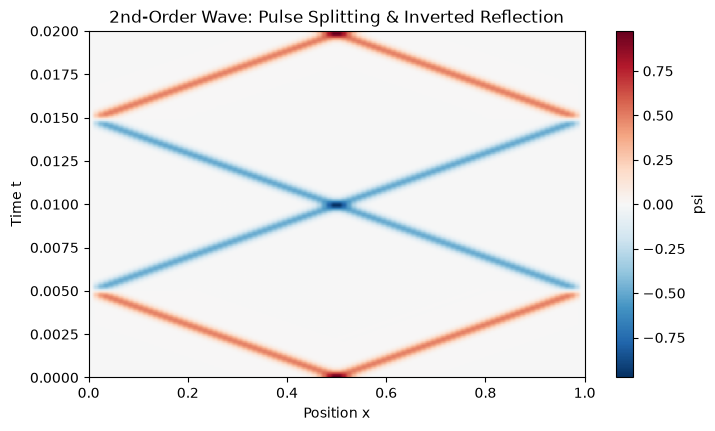

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters (Quiz 2 Reference Code)
N = 100
dx = 0.01
L = N * dx
c = 100.0
dt = 1e-4
k = c * dt / dx         # k = 1.0 (Exact magic time step)
assert k <= 1.0

x = np.linspace(0, L, N)
t_end = 0.02
nt = int(round(t_end / dt))

psi_0 = np.exp(-1000 * (x - L/2)**2)
psi_prev = psi_0.copy()
psi = np.zeros(N)

# First step with zero initial velocity
v0 = np.zeros(N)
for i in range(1, N - 1):
    psi[i] = (k**2 / 2) * (psi_0[i+1] + psi_0[i-1]) + (1 - k**2) * psi_0[i] + dt * v0[i]

psi[0] = 0; psi[-1] = 0
psi_history = [psi_0.copy(), psi.copy()]

# Leap-frog loop
for j in range(2, nt):
    psi_next = np.zeros(N)
    for i in range(1, N - 1):
        psi_next[i] = (k**2) * (psi[i+1] + psi[i-1]) + 2 * (1 - k**2) * psi[i] - psi_prev[i]
    psi_next[0] = 0; psi_next[-1] = 0
    psi_prev = psi.copy()
    psi = psi_next.copy()
    psi_history.append(psi.copy())

plt.figure(figsize=(8, 4.5))
plt.imshow(np.array(psi_history), aspect='auto', origin='lower', extent=[0, L, 0, t_end], cmap='RdBu_r')
plt.colorbar(label='psi')
plt.xlabel('Position x'); plt.ylabel('Time t')
plt.title('2nd-Order Wave: Pulse Splitting & Inverted Reflection')
plt.show()

---
## Class Notebook Code (`n+1/2ndorderwaveeqn.ipynb`)
Exact code from class for the 2nd-order wave equation.

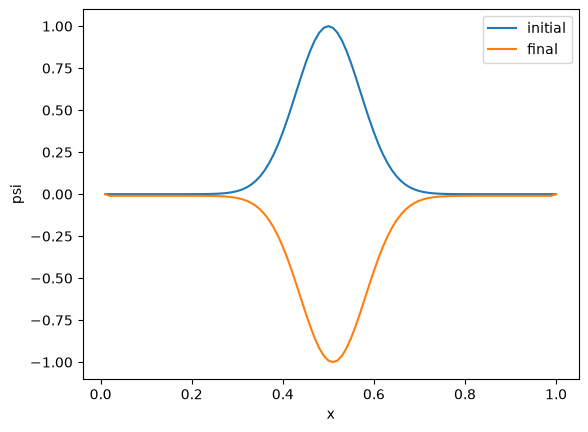

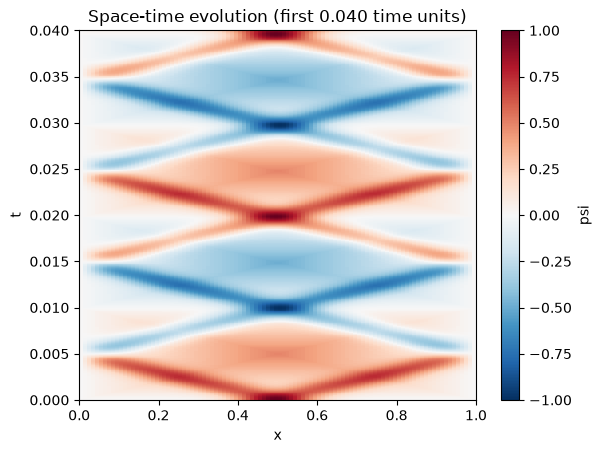

In [2]:
import numpy as np 
import matplotlib.pyplot as plt

# Parameters
N = 100
t_end = 100
dt = 10**(-4)
dx = 10**(-2)
L = N * dx
x = np.arange(dx, L+dx/2, dx)
v = 100
k = v * dt / dx
nt = int(round(t_end / dt))
heat_steps = 400       # steps recorded for the heatmap (~2 bounce periods)
v_not = 0

# Initial Conditions
psi = np.exp(-100 * (x - L/2)**2)
psi_0 = psi.copy()
psi_temp = np.zeros(N)
psi_prev = np.zeros(N)
psi_T = [psi.copy()]   # snapshots for the space-time heatmap

for i in range(1, N-1):
    psi_temp[i] = (k**2 / 2)*(psi[i+1] + psi[i-1]) + (1 - k**2)*psi[i] + dt*v

psi_prev = psi
psi = psi_temp
psi_T.append(psi.copy())

for j in range(1, nt):
    psi_temp = np.zeros(N)
    for i in range(1, N-1):
        psi_temp[i] = (k**2)*(psi[i+1] + psi[i-1]) + 2*(1-k**2)*psi[i] - psi_prev[i]
    psi_prev = psi
    psi = psi_temp
    if j < heat_steps:
        psi_T.append(psi.copy())

plt.plot(x, psi_0, label='initial')
plt.plot(x, psi, label='final')
plt.xlabel('x')
plt.ylabel('psi')
plt.legend()
plt.show()

# Space-time evolution during the first heat_steps steps
psi_T = np.array(psi_T)
t_heat = (len(psi_T) - 1) * dt
vmax = np.max(np.abs(psi_T))

plt.imshow(psi_T, aspect='auto', origin='lower',
           extent=[0, L, 0, t_heat], cmap='RdBu_r',
           vmin=-vmax, vmax=vmax, interpolation='nearest')
plt.colorbar(label='psi')
plt.xlabel('x')
plt.ylabel('t')
plt.title(f'Space-time evolution (first {t_heat:.3f} time units)')
plt.show()